# Helicoper Prison Escapes

In this notebook we will explore data scraped from Wikipedia detailing helicopter prison escapes from 1971-2020. We will investigate the following questions using this dataset:
- Which year and countries had the most helicopter prison break attempts?
- Which countries had the highest rate of escape success?
- Were there more successful or failed escapes overall?
- Which escapees have attempted to escape more than once? How often were they successful?
- Which prisons had the most and least escapee attempts?

## Viewing the Data

In [8]:
# https://www.dataquest.io/projects/portfolio-project-a-prison-break/
import pandas as pd
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_helicopter_prison_escapes"

# change user agent to prevent 403 error
headers = {"User-Agent": "Mozilla/5.0"}
response = requests.get(url, headers=headers)

df = pd.read_html(StringIO(response.text))[1]

In [9]:
df.head()

,Date,Prison name,Country,Succeeded,Escapee(s),Details
0,"August 19, 1971",Santa Martha Acatitla,Mexico,Yes,Joel David Kaplan Carlos Antonio Contreras Castro,Kaplan was a New York businessman who had been...
1,"October 31, 1973","Mountjoy Jail, Dublin",Ireland,Yes,JB O'Hagan Seamus Twomey Kevin Mallon,An IRA member hijacked a helicopter and forced...
2,"May 24, 1978","United States Penitentiary, Marion, Illinois",United States,No,Garrett Brock Trapnell Martin Joseph McNally J...,43-year-old Barbara Ann Oswald hijacked a Sain...
3,"February 27, 1981","Fleury-Mérogis, Essonne, Île-de-France",France,Yes,Gérard Dupré Daniel Beaumont,"With the help of Serge Coutel, Dupré and Beaum..."
4,"May 7, 1981","Orsainville Prison, Quebec City",Canada,No,Marina Paquet (hijacker) Giles Arseneault (pri...,Paquet held a sawed-off shotgun against the ba...


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Date         50 non-null     str  
 1   Prison name  50 non-null     str  
 2   Country      50 non-null     str  
 3   Succeeded    50 non-null     str  
 4   Escapee(s)   50 non-null     str  
 5   Details      50 non-null     str  
dtypes: str(6)
memory usage: 31.7 KB


In [11]:
df.describe()

,Date,Prison name,Country,Succeeded,Escapee(s),Details
count,50,50,50,50,50,50
unique,50,46,16,2,41,50
top,"August 19, 1971","Cárcel Bellavista, Bello, Colombia",France,Yes,—,Kaplan was a New York businessman who had been...
freq,1,2,15,36,8,1


In [12]:
df.isna().value_counts()

Date   Prison name  Country  Succeeded  Escapee(s)  Details
False  False        False    False      False       False      50
Name: count, dtype: int64

In [13]:
df.value_counts('Escapee(s)').head()

Escapee(s)
—                                                    8
Michel Vaujour                                       2
Pascal Payet                                         2
Joel David Kaplan Carlos Antonio Contreras Castro    1
JB O'Hagan Seamus Twomey Kevin Mallon                1
Name: count, dtype: int64

The data appears to be fairly clean. There are no null values, and dashes are used as a placeholder for entries with no info provided.

## Attempts per Year

In [14]:
# separate year into another column
df['Year'] = df['Date'].apply(lambda x: x[-4:]).astype(int)

attempts_per_year = df['Year'].value_counts().sort_index()
attempts_per_year = attempts_per_year.reindex(range(2020, 1970, -1), fill_value=0)
attempts_per_year.head()

Year
2020    1
2019    0
2018    1
2017    0
2016    1
Name: count, dtype: int64

(1970.0, 2021.0)

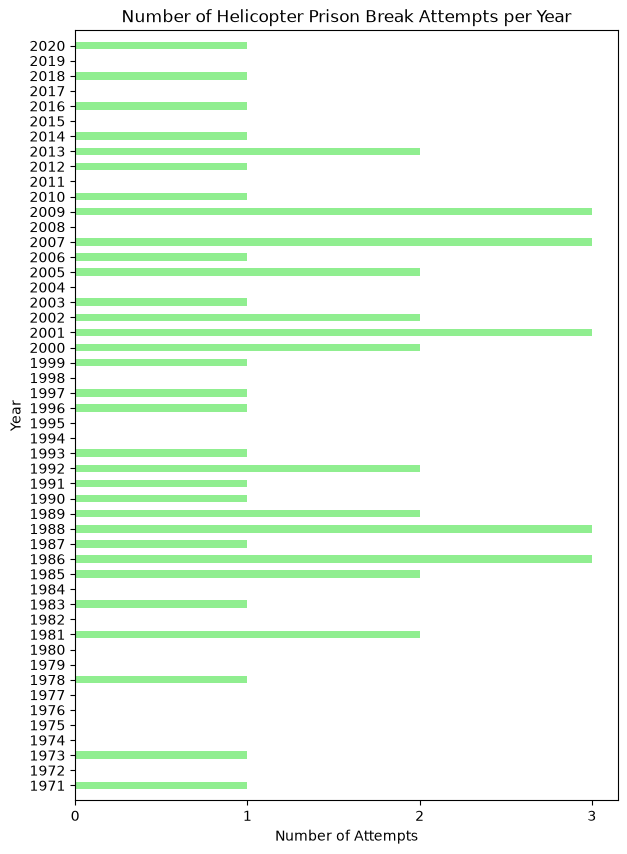

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 10))
ax.barh(attempts_per_year.index, attempts_per_year.values, height=0.5, color='lightgreen')

ax.set_title('Number of Helicopter Prison Break Attempts per Year')
ax.set_ylabel('Year')
ax.set_xlabel('Number of Attempts')

ax.set_xticks([0, 1, 2, 3])
ax.set_yticks(attempts_per_year.index)
ax.set_ylim(1970, 2021)

In [16]:
attempts_per_year[attempts_per_year == 3].index

Index([2009, 2007, 2001, 1988, 1986], dtype='int64', name='Year')

The highest number of escapes attempted per year is 3, which occured during 5 different years: 2009, 2007, 2001, 1988, and 1986.

## Attempts by Country

In [17]:
attempts_by_country = df['Country'].value_counts()
attempts_by_country

Country
France            15
United States      8
Canada             4
Greece             4
Belgium            4
Australia          2
Brazil             2
United Kingdom     2
Colombia           2
Mexico             1
Ireland            1
Italy              1
Puerto Rico        1
Chile              1
Netherlands        1
Russia             1
Name: count, dtype: int64

In [18]:
print((15 / attempts_by_country.sum()) * 100)
print((8 / attempts_by_country.sum()) * 100)

30.0
16.0


15 escape attempts were from France, the highest number out of all the countries. This accounts for 30% of the total number of escape attempts. The US had the second highest number at 8 attempts, or 16% of the total.

Text(0, 0.5, 'Country')

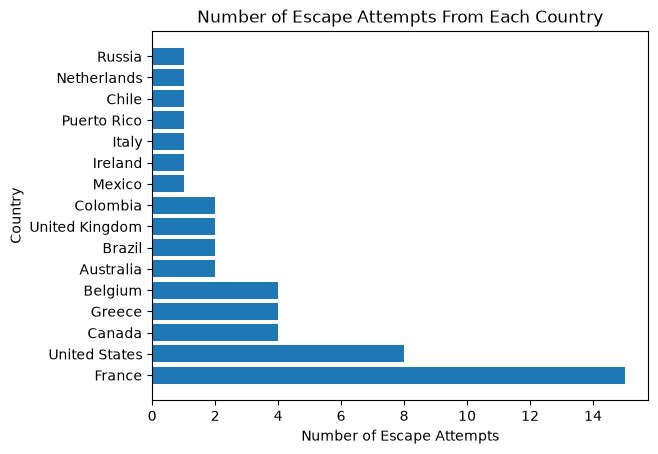

In [19]:
fig, ax = plt.subplots()
ax.barh(attempts_by_country.index, attempts_by_country.values)

ax.set_title('Number of Escape Attempts From Each Country')
ax.set_xlabel('Number of Escape Attempts')
ax.set_ylabel('Country')

## Success by Country

In [31]:
success_by_country = df.groupby(['Country', 'Succeeded'])['Succeeded'].count().unstack().fillna(0)
success_by_country

Succeeded,No,Yes
Country,,
Australia,1.0,1.0
Belgium,2.0,2.0
Brazil,0.0,2.0
Canada,1.0,3.0
Chile,0.0,1.0
Colombia,0.0,2.0
France,4.0,11.0
Greece,2.0,2.0
Ireland,0.0,1.0


Text(0.5, 1.0, 'Escape Successes and Failures by Country')

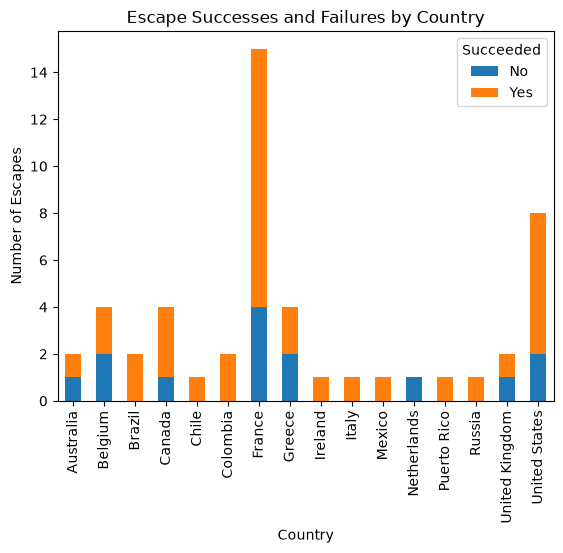

In [44]:
success_by_country.plot.bar(stacked=True)
plt.ylabel('Number of Escapes')
plt.title('Escape Successes and Failures by Country')

Most escape attempts were successful. All countries had at least a 50% success rate except for the Netherlands which had a singular failed attempt. In conclusion, it is statistically better to try escaping than not.

## Repeat Escapees
Since there are no commas or newlines separating each individual's names, it will be a bit tricky to parse distinct names. We will try separating the strings into chunks of 2 words each which represent the first and last name, then look for any duplicates that appear.

In [88]:
chunks = []
for string in df[df['Escapee(s)'] != '—']['Escapee(s)']: # filter out the dashes
    words = string.split()
    chunks += [" ".join(words[i:i+2]) for i in range(0, len(words), 2)]

print(chunks)

['Joel David', 'Kaplan Carlos', 'Antonio Contreras', 'Castro', "JB O'Hagan", 'Seamus Twomey', 'Kevin Mallon', 'Garrett Brock', 'Trapnell Martin', 'Joseph McNally', 'James Kenneth', 'Johnson', 'Gérard Dupré', 'Daniel Beaumont', 'Marina Paquet', '(hijacker) Giles', 'Arseneault (prisoner)', 'David McMillan', 'James Rodney', 'Leonard William', 'Douglas Ballew', 'Jesse Glenn', 'Smith', 'José Carlos', 'dos Reis', 'Encina, a.k.a.', '"Escadinha"', 'Michel Vaujour', 'Samantha Lopez', 'André Bellaïche', 'Gianluigi Esposito', 'Luciano Cipollari', 'Sydney Draper', 'John Kendall', 'Danny Mahoney', 'Francis Mitchell', 'Randy Lackey', 'Dandeny Muñoz', 'Brances Muñoz', 'Ben Kramer', 'Ralph Brown', 'Freddie Gonzales', 'Robert Ford', 'David Thomas', 'William Lane', 'Michel Vaujour', 'Four members', 'of the', 'Manuel Rodriguez', 'Patriotic Front', 'John Killick', 'Steven Whitsett', 'Pascal Payet', 'Abdelhamid Carnous', 'Emile Forma-Sari', 'Jean-Philippe Lecase', 'Orlando Cartagena', 'Jose Rodriguez', 'Vi

In the output, are a few issues in cases such as:
- People with a middle name (Joel David Kaplan)
- Longer names and aliases (José Carlos dos Reis Encina, a.k.a. "Escadinha")
- Descriptions (Four members of the Manuel Rodriguez Patriotic Front)
- Parentheses (Marina Paquet (hijacker))

However, for the most part this rudimentary grouping was successful. The first and last name format applies to the majority of names and there is no good way to separate out the edge cases without combing through it manually (that I can think of).

In [86]:
first_last_names = pd.Series(chunks)
first_last_names.value_counts()

Michel Vaujour     2
Pascal Payet       2
Alket Rizai        2
Joel David         1
Kaplan Carlos      1
                  ..
Serge Pomerleau    1
Pola Roupa         1
Nikos Maziotis     1
Rédoine Faïd       1
Kristel A.         1
Name: count, Length: 89, dtype: int64

From this list we can identify 3 repeat escapees: Michel Vaujour, Pascal Payet, and Alket Rizai. Each prisoner has 2 escape attempts on their record.

In [104]:
df[df['Escapee(s)'].str.contains('Michel Vaujour|Pascal Payet|Alket Rizai', na=False)]

,Date,Prison name,Country,Succeeded,Escapee(s),Details,Year
8,"May 26, 1986",Prison de la Santé,France,Yes,Michel Vaujour,Vaujour had 28 years to serve for attempted mu...,1986
21,"June 17, 1993","Touraine Central Prison, Tours",France,No,Michel Vaujour,Vaujour and his wife were imprisoned in 1991. ...,1993
27,"January 19, 2001",Luynes prison,France,Yes,Pascal Payet,Payet escaped using a hijacked helicopter.[7],2001
35,"June 6, 2006",Korydallos Prison,Greece,Yes,Vassilis Paleokostas Alket Rizai,Nikos Paleokostas and another man hijacked a h...,2006
37,"July 15, 2007",Grasse prison,France,Yes,Pascal Payet,Payet escaped for the third time using a helic...,2007
39,"February 22, 2009",Korydallos Prison,Greece,Yes,Vasilis Paleokostas Alket Rizai,The two men escaped from the prison by helicop...,2009


With the exception of Michel Vaujour who failed 1 of his escape attempts, all of the escapes attempted by the repeat escapees were successful. A potential explanation is that the experience gained from the first attempt makes the second attempt more likely to succeed.

## Easiest and Hardest Prisons to Escape From

In [125]:
prison_success = df.groupby(['Prison name', 'Succeeded'])['Succeeded'].value_counts().unstack().fillna(0)
prison_success.sort_values('No', ascending=False).head()

Succeeded,No,Yes
Prison name,,
"Touraine Central Prison, Tours",2.0,0.0
De Geerhorst prison,1.0,0.0
"Forest prison, Brussels",1.0,0.0
France,1.0,0.0
Fresnes prison,1.0,0.0


In [123]:
prison_success.sort_values('Yes', ascending=False).head()

Succeeded,No,Yes
Prison name,,
"Cárcel Bellavista, Bello, Colombia",0.0,2.0
Korydallos Prison,0.0,2.0
Luynes prison,0.0,2.0
Bruges,0.0,1.0
"Arkansas Valley Correctional Facility, Colorado",0.0,1.0


Touraine Central Prison, Tours is the hardest prison to escape from, with 2 failures and no successes. Cárcel Bellavista, Bello, Colombia, Korydallos Prison, and Luynes prison are the easiest to escape from, each with 2 success and no failures. If arrested, try to have your attorney get you placed in one of these three prisons for the best chance of prematurely regaining your freedom :)